In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from glmpca import glmpca
import torch

import gaston
from gaston import neural_net, cluster_plotting, dp_related, segmented_fit, restrict_spots, model_selection
from gaston import binning_and_plotting, isodepth_scaling, run_slurm_scripts, parse_adata
from gaston import spatial_gene_classification, plot_cell_types, filter_genes, process_NN_output

import seaborn as sns
import math


/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/dask/dataframe/_pyarrow_compat.py:17: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
data_dir = Path("../data")
plot_dir = Path("../plots")
plot_dir.mkdir(parents=True, exist_ok=True)

counts_csv = data_dir / "ca3_simulated_dataset_peakt_1_sd.r_0p5_rep_04.csv"
coords_csv = data_dir / "ca3_xy.csv"

#counts_npy = data_dir / "ca3_counts_peakt_2_rep_01.npy"
#coords_npy = data_dir / "ca3_coords.npy"
#gene_labels_npy = data_dir / "ca3_gene_labels.npy"
#glmpca_npy = data_dir / "ca3_glmpca_peakt_2_rep_01.npy"

out_dir = "../data/gaston_outputs/ca3_gaston_outputs_peakt_2_rep_01"

use_RGB = False
np.random.seed(1)
torch.manual_seed(1)


In [4]:
counts_df = pd.read_csv(counts_csv, index_col=0)
coords_df = pd.read_csv(coords_csv)

counts_mat = counts_df.to_numpy(dtype=np.int64)  # G x N: genes by spots
coords_mat = coords_df[["xcoord", "ycoord"]].to_numpy(dtype=np.float64)  # N x 2
gene_labels = counts_df.index.astype(str).to_numpy()

if counts_mat.shape[1] != coords_mat.shape[0]:
    raise ValueError(
        f"Counts columns ({counts_mat.shape[1]}) must match coordinate rows ({coords_mat.shape[0]})."
    )

#np.save(counts_npy, counts_mat)
#np.save(coords_npy, coords_mat)
#np.save(gene_labels_npy, gene_labels)

print("counts_mat", counts_mat.shape)
print("coords_mat", coords_mat.shape)
print("gene_labels", gene_labels.shape)


counts_mat (1000, 1456)
coords_mat (1456, 2)
gene_labels (1000,)


In [6]:
num_dims = 5
penalty = 20

num_iters = 30
eps = 1e-4
num_genes = counts_mat.shape[0]

counts_mat_spot_by_gene = counts_mat.T
top_gene_ix = np.argsort(np.sum(counts_mat_spot_by_gene, axis=0))[-num_genes:]
counts_mat_glmpca = counts_mat_spot_by_gene[:, top_gene_ix]

glmpca_res = glmpca.glmpca(
    counts_mat_glmpca.T,
    num_dims,
    fam="poi",
    penalty=penalty,
    verbose=True,
    ctl={"maxIter": num_iters, "eps": eps, "optimizeTheta": True},
)

A = glmpca_res["factors"]  # N x num_dims

if use_RGB:
    A = np.hstack((A, rgb_mean))

#np.save(glmpca_npy, A)
print("A", A.shape)


Iteration: 0 | deviance=1.7310E+6
Iteration: 1 | deviance=1.7310E+6
Iteration: 2 | deviance=1.7310E+6
Iteration: 3 | deviance=1.7144E+6
Iteration: 4 | deviance=1.6990E+6
Iteration: 5 | deviance=1.6964E+6
Iteration: 6 | deviance=1.6958E+6
Iteration: 7 | deviance=1.6956E+6
A (1456, 5)


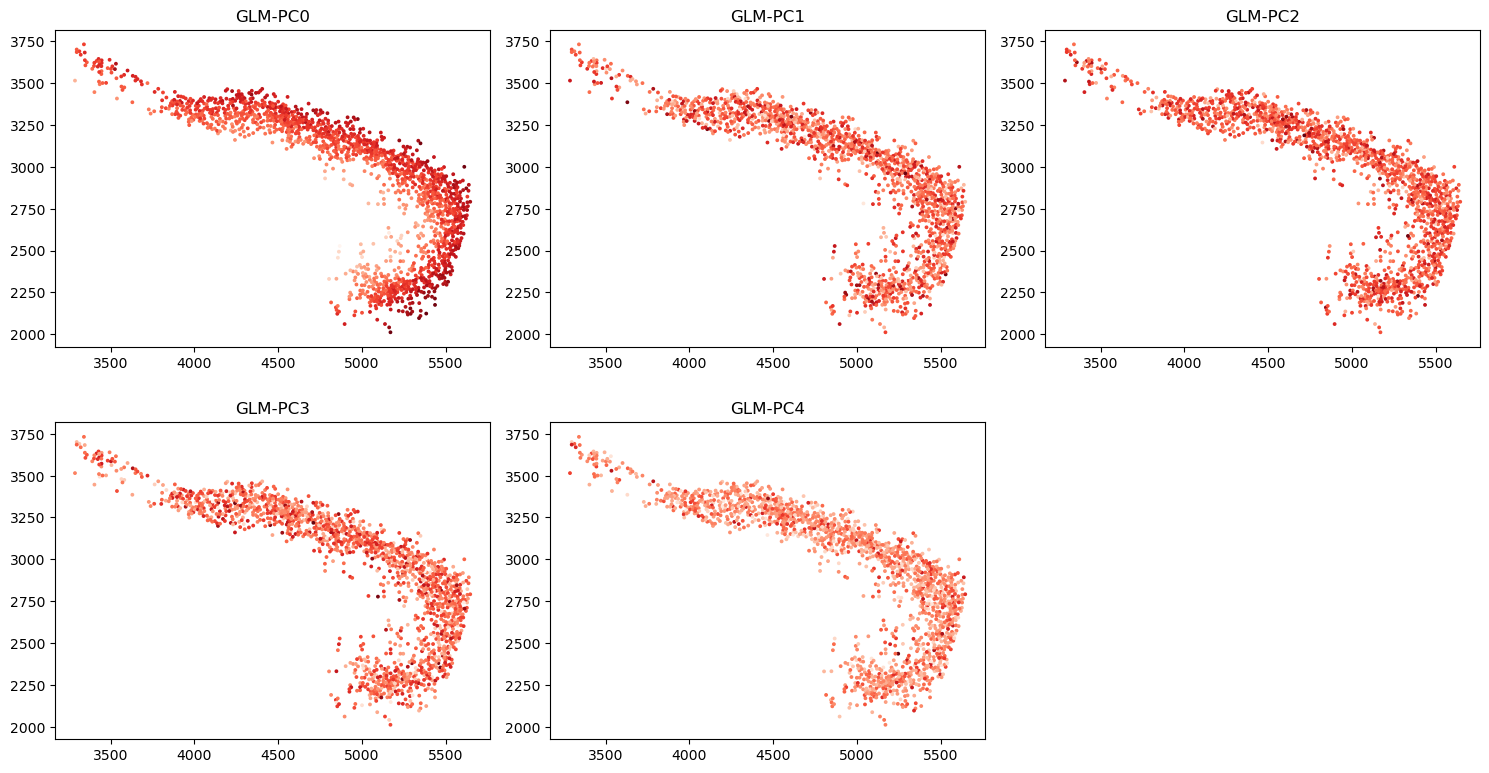

In [7]:
rotated_coords = dp_related.rotate_by_theta(coords_mat, 0)

n_panels = A.shape[1]
n_cols = 3
n_rows = int(np.ceil(n_panels / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)

for i, ax in enumerate(axs.ravel()):
    if i < n_panels:
        ax.scatter(rotated_coords[:, 0], rotated_coords[:, 1], c=A[:, i], cmap="Reds", s=3)
        ax.set_title(f"GLM-PC{i}")
        ax.set_aspect("equal")
    else:
        ax.axis("off")

plt.tight_layout()
plt.savefig(plot_dir / "ca3_glmpca_components_peakt_1_rep_01.png", dpi=300, bbox_inches="tight")
plt.show()


In [8]:
S = coords_mat

S_torch, A_torch = neural_net.load_rescale_input_data(S, A)

isodepth_arch = [20, 20]
expression_fn_arch = [20, 20]

num_epochs = 10000
checkpoint = 500
optimizer = "adam"
num_restarts = 2 #Change this as needed 

for seed in range(num_restarts):
    print(f"training neural network for seed {seed}")
    out_dir_seed = f"{out_dir}/rep{seed}"
    os.makedirs(out_dir_seed, exist_ok=True)

    mod, loss_list = neural_net.train(
        S_torch,
        A_torch,
        S_hidden_list=isodepth_arch,
        A_hidden_list=expression_fn_arch,
        epochs=num_epochs,
        checkpoint=checkpoint,
        save_dir=out_dir_seed,
        optim=optimizer,
        seed=seed,
        save_final=True,
    )


training neural network for seed 0
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500
training neural network for seed 1
Training on device: cpu
epoch: 0
epoch: 500
epoch: 1000
epoch: 1500
epoch: 2000
epoch: 2500
epoch: 3000
epoch: 3500
epoch: 4000
epoch: 4500
epoch: 5000
epoch: 5500
epoch: 6000
epoch: 6500
epoch: 7000
epoch: 7500
epoch: 8000
epoch: 8500
epoch: 9000
epoch: 9500


In [9]:
gaston_model, A_processed, S_processed = process_NN_output.process_files(out_dir)

num_layers = 1
gaston_isodepth, gaston_labels = dp_related.get_isodepth_labels(
    gaston_model,
    A_processed,
    S_processed,
    num_layers,
)

flip_isodepth = False
if flip_isodepth:
    gaston_isodepth = np.max(gaston_isodepth) - gaston_isodepth
    gaston_labels = (num_layers - 1) - gaston_labels

print("gaston_isodepth", gaston_isodepth.shape)
print("gaston_labels", gaston_labels.shape)



best model: ../data/gaston_outputs/ca3_gaston_outputs_peakt_2_rep_01/rep0
gaston_isodepth (1456,)
gaston_labels (1456,)


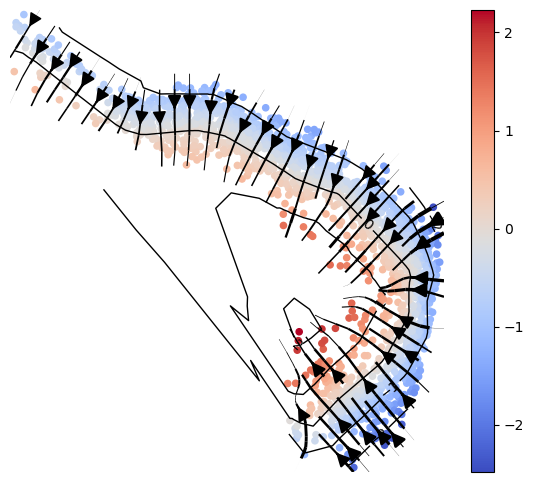

In [10]:
show_streamlines = True
rotate = 0
arrowsize = 2

cluster_plotting.plot_isodepth(
    gaston_isodepth,
    S_processed,
    gaston_model,
    figsize=(7, 6),
    streamlines=show_streamlines,
    rotate=rotate,
    arrowsize=arrowsize,
    neg_gradient=flip_isodepth,
)

plt.savefig(plot_dir / "ca3_gaston_isodepth_peakt_1_rep_01.png", dpi=300, bbox_inches="tight")
plt.show()

np.savetxt(data_dir / "ca3_gaston_isodepth_peakt_1_rep_01.csv", gaston_isodepth, delimiter=",")

pd.DataFrame(
    {
        "gaston_isodepth": gaston_isodepth,
        "gaston_label": gaston_labels,
    }
).to_csv(data_dir / "ca3_gaston_results_peakt_1_rep_01.csv", index=False)


In [11]:
# CHANGE FOR YOUR APPLICATION: use number of domains from above!
num_layers=1

# identify labels
gaston_isodepth, gaston_labels=dp_related.get_isodepth_labels(gaston_model,A,S,num_layers)

# DATASET-SPECIFIC: so domains are ordered oligodendrocyte to molecular, with increasing isodepth
gaston_isodepth=np.max(gaston_isodepth) - gaston_isodepth
gaston_labels=(num_layers-1)-gaston_labels

In [12]:
# Spatially variable gene analysis using GASTON's one-layer linear model
# Based on the cerebellum tutorial's segmented_fit.pw_linear_fit workflow.

# segmented_fit.pw_linear_fit expects counts as N x G: spots by genes.
counts_mat_for_pw = counts_mat
if counts_mat_for_pw.shape[0] != len(gaston_isodepth):
    counts_mat_for_pw = counts_mat_for_pw.T

if counts_mat_for_pw.shape[0] != len(gaston_isodepth):
    raise ValueError(
        f"Counts rows ({counts_mat_for_pw.shape[0]}) must match isodepth length ({len(gaston_isodepth)})."
    )

if counts_mat_for_pw.shape[1] != len(gene_labels):
    raise ValueError(
        f"Counts columns ({counts_mat_for_pw.shape[1]}) must match gene labels ({len(gene_labels)})."
    )

num_layers = 1
if len(np.unique(gaston_labels)) != num_layers:
    raise ValueError(f"Expected {num_layers} GASTON layer, found labels {np.unique(gaston_labels)}.")

# No cell-type-specific effects for this simulated dataset.
cell_type_df = None
ct_list = []

# Tutorial parameters. With one layer, this is a single linear Poisson regression per gene.
tutorial_t = 0.1  # tutorial threshold: set slope to 0 if LLR p-value >= tutorial_t
umi_threshold = 0
zero_fit_threshold = 0
idx_kept = np.arange(counts_mat_for_pw.shape[1])
isodepth_mult_factor = 0.1

# Use t=np.inf to keep the fitted alternative-model slope for every finite fit.
# We compute the tutorial-thresholded slope afterward without refitting.
pw_fit_dict = segmented_fit.pw_linear_fit(
    counts_mat_for_pw,
    gaston_labels,
    gaston_isodepth,
    cell_type_df,
    ct_list,
    idx_kept=idx_kept,
    zero_fit_threshold=zero_fit_threshold,
    t=np.inf,
    umi_threshold=umi_threshold,
    isodepth_mult_factor=isodepth_mult_factor,
)

slope_mat, intercept_mat, discont_mat, pv_mat = pw_fit_dict["all_cell_types"]

if slope_mat.shape[1] != 1:
    raise ValueError(f"Expected one slope column for one layer, found {slope_mat.shape[1]} columns.")

slope_unthresholded = slope_mat[:, 0]
p_values = pv_mat[:, 0]
slope_tutorial_thresholded = np.where(p_values < tutorial_t, slope_unthresholded, 0.0)

isodepth_range = np.ptp(gaston_isodepth)
isodepth_sd = np.std(gaston_isodepth)

print(f"isodepth min/max: {np.min(gaston_isodepth):.6g}, {np.max(gaston_isodepth):.6g}")
print(f"isodepth range: {isodepth_range:.6g}")
print(f"isodepth sd: {isodepth_sd:.6g}")
print("Raw slopes are per one raw GASTON isodepth unit; standardized/range-scale columns are often easier to read.")

gene_slopes = pd.DataFrame(
    {
        "gene": gene_labels[idx_kept],
        "slope": slope_unthresholded,
        "slope_tutorial_thresholded": slope_tutorial_thresholded,
        "slope_per_isodepth_sd": slope_unthresholded * isodepth_sd,
        "log_fc_across_isodepth_range": slope_unthresholded * isodepth_range,
        "intercept": intercept_mat[:, 0],
        "p_value": p_values,
        "total_umi": counts_mat_for_pw[:, idx_kept].sum(axis=0),
        "nonzero_spots": (counts_mat_for_pw[:, idx_kept] > 0).sum(axis=0),
    }
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
print(gene_slopes.to_string(index=False))


Poisson regression for ALL cell types


100%|██████████| 1000/1000 [00:04<00:00, 203.60it/s]

isodepth min/max: 0, 6865.15
isodepth range: 6865.15
isodepth sd: 1419.03
Raw slopes are per one raw GASTON isodepth unit; standardized/range-scale columns are often easier to read.
gene         slope  slope_tutorial_thresholded  slope_per_isodepth_sd  log_fc_across_isodepth_range  intercept      p_value  total_umi  nonzero_spots
   1  3.605380e-05                    0.000000               0.051162                      0.247515  -8.463878 2.167526e-01        596            471
   2 -3.691663e-05                   -0.000037              -0.052386                     -0.253438  -6.926489 1.716384e-02       2023           1059
   3  3.746771e-05                    0.000037               0.053168                      0.257222  -7.776945 6.959372e-02       1192            810
   4  1.097550e-05                    0.000000               0.015575                      0.075348  -7.210859 5.020272e-01       1870           1011
   5 -1.123948e-07                    0.000000              -0.00015

In [15]:
gene_slopes_ranked = (
    gene_slopes
    .assign(abs_slope=gene_slopes["slope"].abs())
    .sort_values("abs_slope", ascending=False)
    .reset_index(drop=True)
)

gene_slopes_ranked["abs_slope_rank"] = np.arange(1, len(gene_slopes_ranked) + 1)

gene_1_rank = int(
    gene_slopes_ranked.loc[
        gene_slopes_ranked["gene"].astype(str) == "1",
        "abs_slope_rank"
    ].iloc[0]
)

print(f"Rank of gene 1 by decreasing absolute slope: {gene_1_rank}")
display(gene_slopes_ranked.head(25))

Rank of gene 1 by decreasing absolute slope: 146


,gene,slope,slope_tutorial_thresholded,slope_per_isodepth_sd,log_fc_across_isodepth_range,intercept,p_value,total_umi,nonzero_spots,slope_rank,abs_slope,abs_slope_rank
0,516,-0.000129,-0.000129,-0.182668,-0.883729,-9.034002,0.013971,168,156,1000.0,0.000129,1
1,692,0.000093,0.000093,0.132542,0.641224,-9.905218,0.082601,182,168,1.0,0.000093,2
2,82,0.000093,0.000093,0.131637,0.636850,-9.457382,0.031243,284,250,2.0,0.000093,3
3,481,-0.000092,-0.000092,-0.131095,-0.634226,-8.457217,0.012072,347,310,999.0,0.000092,4
4,674,-0.000092,-0.000092,-0.130704,-0.632333,-8.375436,0.009100,377,320,998.0,0.000092,5
5,568,0.000083,0.000083,0.117669,0.569272,-9.696165,0.093587,214,199,3.0,0.000083,6
6,948,-0.000082,-0.000082,-0.116638,-0.564281,-8.641604,0.038084,301,275,997.0,0.000082,7
7,429,-0.000081,-0.000081,-0.115154,-0.557102,-8.868259,0.067009,241,214,996.0,0.000081,8
8,911,0.000081,0.000081,0.114866,0.555711,-8.745192,0.008706,549,462,4.0,0.000081,9
9,461,-0.000081,-0.000081,-0.114560,-0.554231,-8.048518,0.006007,548,451,995.0,0.000081,10


gene    slope  slope_tutorial_thresholded  slope_per_isodepth_sd  log_fc_across_isodepth_range  intercept  p_value  total_umi  nonzero_spots
   1 0.000036                         0.0               0.051162                      0.247515  -8.463878 0.216753        596            471


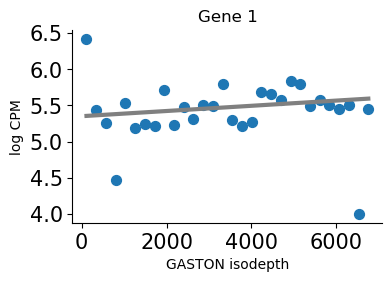

gene     slope  slope_tutorial_thresholded  slope_per_isodepth_sd  log_fc_across_isodepth_range  intercept  p_value  total_umi  nonzero_spots
   2 -0.000037                   -0.000037              -0.052386                     -0.253438  -6.926489 0.017164       2023           1059


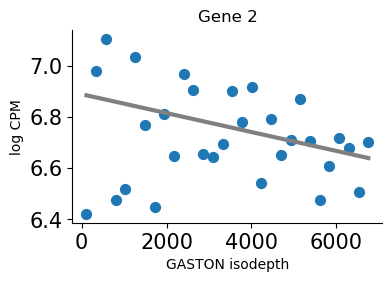

In [13]:
# Plot binned expression and fitted one-layer GASTON expression function for genes 1 and 2.
# This follows the tutorial's bin_data(...) + plot_gene_pwlinear(...) pattern.

genes_to_plot = ["1", "2"]
domain_colors = ["C0"]
offset = 10**6  # log CPM, as in the tutorial

missing_genes = [gene for gene in genes_to_plot if gene not in gene_labels]
if missing_genes:
    raise ValueError(f"Genes not found in gene_labels: {missing_genes}")

binning_output = binning_and_plotting.bin_data(
    counts_mat_for_pw,
    gaston_labels,
    gaston_isodepth,
    cell_type_df,
    gene_labels,
    num_bins_per_domain=[30],
    idx_kept=idx_kept,
    umi_threshold=umi_threshold,
)

for gene_name in genes_to_plot:
    print(gene_slopes.loc[gene_slopes["gene"] == gene_name].to_string(index=False))

    binning_and_plotting.plot_gene_pwlinear(
        gene_name,
        pw_fit_dict,
        gaston_labels,
        gaston_isodepth,
        binning_output,
        cell_type_list=None,
        pt_size=50,
        colors=domain_colors,
        linear_fit=True,
        ticksize=15,
        figsize=(4, 2.5),
        offset=offset,
        lw=3,
        domain_boundary_plotting=False,
    )
    plt.title(f"Gene {gene_name}")
    plt.xlabel("GASTON isodepth")
    plt.ylabel("log CPM")
    plt.show()
